# Day 042 | Random Forest
## 100 Days of ML for Geotechnical Engineering
**Phase:** Classical Machine Learning

**Author:** Ripon Chandra Malo  
**Date:** 2026-05-16  

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Random Forest | Ensemble of many decision trees | Combine 100 soil engineers' opinions for a robust prediction |
| Bagging | Train each tree on a random subset of data | Each engineer reviews a different subset of site reports |
| Out-of-Bag score | Validation using samples not seen by each tree | Test each engineer on the reports they did NOT review |
| Feature importance | Which inputs matter most | Is N-value or footing width more important for bearing capacity? |
| n_estimators | Number of trees in the forest | How many engineers to consult |
| max_depth | Maximum depth of each tree | How detailed each engineer's analysis can be |

---

## Our Geotechnical Problem

A geotechnical engineer needs to predict the **bearing capacity** (kPa) of shallow foundations based on:

- **Footing width** (m)
- **Footing depth** (m)
- **N-value** from SPT testing
- **Soil unit weight** (kN/m\u00b3)
- **Cohesion** (kPa)
- **Friction angle** (degrees)

Yesterday we used a single decision tree. Today we build a **forest** of trees that vote together, dramatically improving prediction accuracy and stability.

---

## Part 1: Generate Bearing Capacity Data

In [1]:
# ─────────────────────────────────────────────────────
# IMPORTS
# ─────────────────────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(42)
print("All imports successful.")

All imports successful.


In [2]:
# ─────────────────────────────────────────────────────
# GENERATE BEARING CAPACITY DATA
# ─────────────────────────────────────────────────────

n_samples = 120

footing_width = np.round(np.random.uniform(0.5, 4.0, n_samples), 2)
footing_depth = np.round(np.random.uniform(0.5, 3.0, n_samples), 2)
N_value = np.random.randint(5, 50, n_samples)
unit_weight = np.round(np.random.uniform(15.0, 21.0, n_samples), 1)
cohesion = np.round(np.random.uniform(0, 80, n_samples), 1)
friction_angle = np.round(np.random.uniform(15, 40, n_samples), 1)

# Simplified Terzaghi-inspired bearing capacity formula with noise
# q_u = c*Nc + gamma*D*Nq + 0.5*gamma*B*Ngamma
Nc = 5.14 + 0.3 * (friction_angle - 15)
Nq = 1.0 + 0.15 * (friction_angle - 15) ** 1.3
Ngamma = 0.5 + 0.08 * (friction_angle - 15) ** 1.5

bearing_capacity = (
    cohesion * Nc
    + unit_weight * footing_depth * Nq
    + 0.5 * unit_weight * footing_width * Ngamma
    + N_value * 3.5  # SPT correlation contribution
)
# Add realistic noise (10% coefficient of variation)
noise = np.random.normal(0, 0.10 * bearing_capacity)
bearing_capacity = np.round(np.maximum(bearing_capacity + noise, 30), 1)

df = pd.DataFrame({
    'footing_width': footing_width,
    'footing_depth': footing_depth,
    'N_value': N_value,
    'unit_weight': unit_weight,
    'cohesion': cohesion,
    'friction_angle': friction_angle,
    'bearing_capacity_kPa': bearing_capacity
})

print(f"Dataset shape: {df.shape}")
print(f"\nBearing capacity range: {df['bearing_capacity_kPa'].min():.1f} - {df['bearing_capacity_kPa'].max():.1f} kPa")
print(f"Mean bearing capacity: {df['bearing_capacity_kPa'].mean():.1f} kPa")
print(f"\nFirst 5 rows:")
df.head()

Dataset shape: (120, 7)

Bearing capacity range: 189.8 - 1695.6 kPa
Mean bearing capacity: 707.6 kPa

First 5 rows:


,footing_width,footing_depth,N_value,unit_weight,cohesion,friction_angle,bearing_capacity_kPa
0,1.81,2.52,32,15.6,34.8,32.4,925.8
1,3.83,2.74,34,16.9,20.3,34.9,1050.5
2,3.06,1.30,33,20.9,32.4,26.5,635.1
3,2.60,0.78,10,16.1,45.7,36.1,769.8
4,1.05,1.07,39,15.1,59.3,34.2,950.1


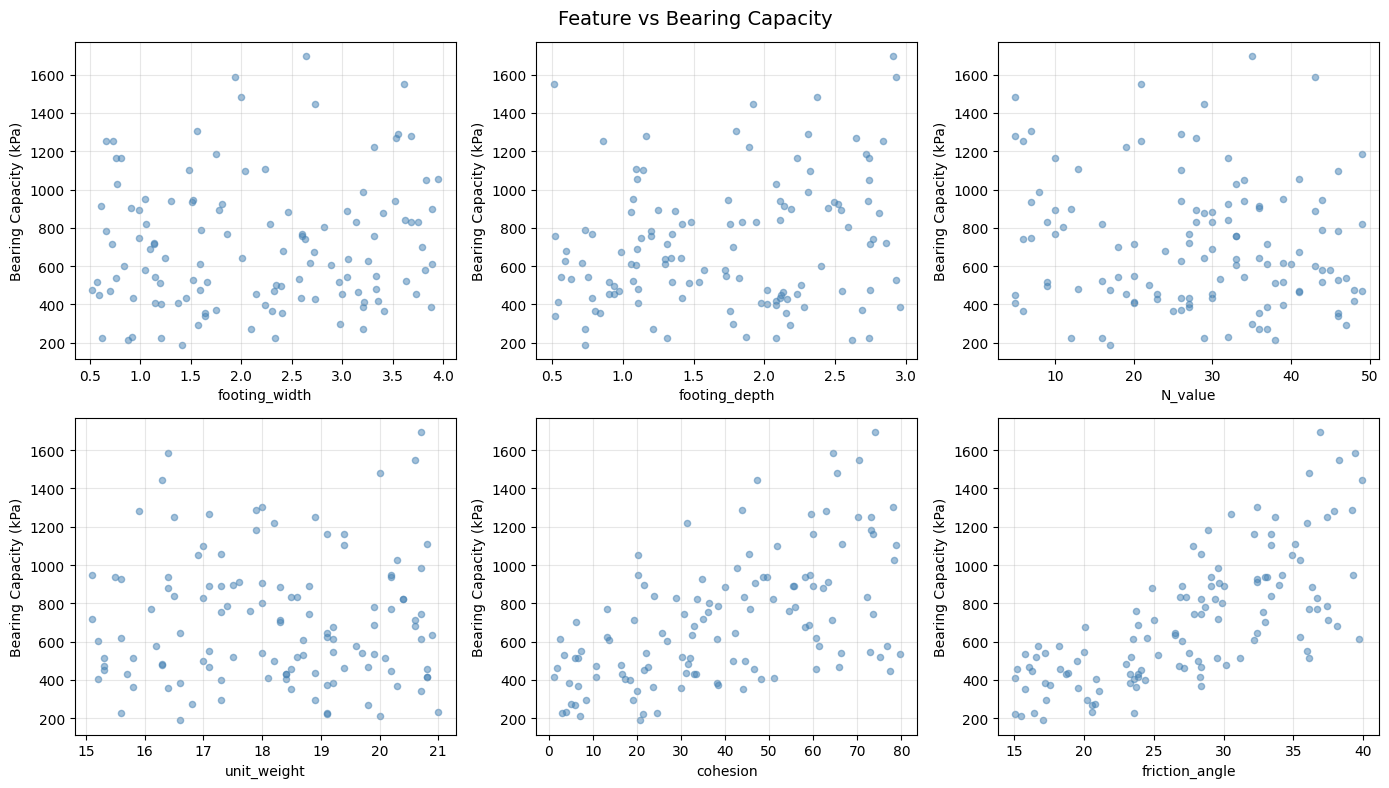

Cohesion and friction angle show the strongest trends,
which matches Terzaghi's bearing capacity theory.


In [3]:
# ─────────────────────────────────────────────────────
# EXPLORE THE DATA
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
features = ['footing_width', 'footing_depth', 'N_value', 'unit_weight', 'cohesion', 'friction_angle']

for ax, feat in zip(axes.ravel(), features):
    ax.scatter(df[feat], df['bearing_capacity_kPa'], alpha=0.5, s=20, color='steelblue')
    ax.set_xlabel(feat)
    ax.set_ylabel('Bearing Capacity (kPa)')
    ax.grid(True, alpha=0.3)

fig.suptitle('Feature vs Bearing Capacity', fontsize=14)
plt.tight_layout()
plt.show()

print("Cohesion and friction angle show the strongest trends,")
print("which matches Terzaghi's bearing capacity theory.")

---

## Part 2: How Random Forests Work — Bagging

A Random Forest uses **bagging** (Bootstrap Aggregating):

1. **Bootstrap**: Draw `n` samples WITH replacement from the training data. Each tree sees ~63% of unique samples.
2. **Random feature subset**: At each split, only consider a random subset of features (typically `sqrt(p)` for classification, `p/3` for regression).
3. **Grow full trees**: Each tree is grown deep (low bias).
4. **Aggregate**: Average all tree predictions (regression) or take majority vote (classification).

**Why it works**: Each tree overfits differently. Averaging many diverse trees cancels out the individual errors, reducing variance while keeping bias low.

**Out-of-Bag (OOB) score**: The ~37% of samples NOT used to train each tree serve as a built-in validation set. The OOB score approximates test set performance without needing a separate validation split.

In [4]:
# ─────────────────────────────────────────────────────
# DEMONSTRATE BOOTSTRAP SAMPLING
# ─────────────────────────────────────────────────────

original = np.arange(10)
print("Original samples:", original)
print()

for i in range(3):
    bootstrap = np.random.choice(original, size=len(original), replace=True)
    oob = np.setdiff1d(original, bootstrap)
    print(f"Tree {i+1} bootstrap: {bootstrap}")
    print(f"  Out-of-bag (unused): {oob}  ({len(oob)/len(original)*100:.0f}% left out)")
    print()

print("Each tree trains on a different random subset.")
print("The left-out samples (OOB) are used for free validation.")

Original samples: [0 1 2 3 4 5 6 7 8 9]

Tree 1 bootstrap: [0 3 8 0 3 5 5 7 0 6]
  Out-of-bag (unused): [1 2 4 9]  (40% left out)

Tree 2 bootstrap: [0 6 2 7 2 0 7 2 1 0]
  Out-of-bag (unused): [3 4 5 8 9]  (50% left out)

Tree 3 bootstrap: [2 1 1 5 0 1 5 2 3 0]
  Out-of-bag (unused): [4 6 7 8 9]  (50% left out)

Each tree trains on a different random subset.
The left-out samples (OOB) are used for free validation.


---

## Part 3: Train Random Forest vs Single Decision Tree

In [5]:
# ─────────────────────────────────────────────────────
# PREPARE DATA
# ─────────────────────────────────────────────────────

feature_cols = ['footing_width', 'footing_depth', 'N_value', 'unit_weight', 'cohesion', 'friction_angle']
X = df[feature_cols]
y = df['bearing_capacity_kPa']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training: {X_train.shape[0]} samples")
print(f"Testing:  {X_test.shape[0]} samples")

Training: 96 samples
Testing:  24 samples


In [6]:
# ─────────────────────────────────────────────────────
# SINGLE TREE vs RANDOM FOREST
# ─────────────────────────────────────────────────────

# Single Decision Tree
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# Random Forest (100 trees)
rf = RandomForestRegressor(n_estimators=100, random_state=42, oob_score=True)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Model Comparison")
print("=" * 55)
print(f"{'Metric':<25s} {'Decision Tree':>13s} {'Random Forest':>13s}")
print("-" * 55)
print(f"{'R-squared':<25s} {r2_score(y_test, y_pred_dt):>13.4f} {r2_score(y_test, y_pred_rf):>13.4f}")
print(f"{'RMSE (kPa)':<25s} {np.sqrt(mean_squared_error(y_test, y_pred_dt)):>13.2f} {np.sqrt(mean_squared_error(y_test, y_pred_rf)):>13.2f}")
print(f"{'MAE (kPa)':<25s} {mean_absolute_error(y_test, y_pred_dt):>13.2f} {mean_absolute_error(y_test, y_pred_rf):>13.2f}")
print(f"{'OOB Score':<25s} {'N/A':>13s} {rf.oob_score_:>13.4f}")
print()
print("Random Forest reduces variance by averaging many trees.")
print(f"OOB Score ({rf.oob_score_:.4f}) approximates test performance without a separate validation set.")

Model Comparison
Metric                    Decision Tree Random Forest
-------------------------------------------------------
R-squared                        0.5833        0.8564
RMSE (kPa)                       217.53        127.69
MAE (kPa)                        159.35         97.19
OOB Score                           N/A        0.7840

Random Forest reduces variance by averaging many trees.
OOB Score (0.7840) approximates test performance without a separate validation set.


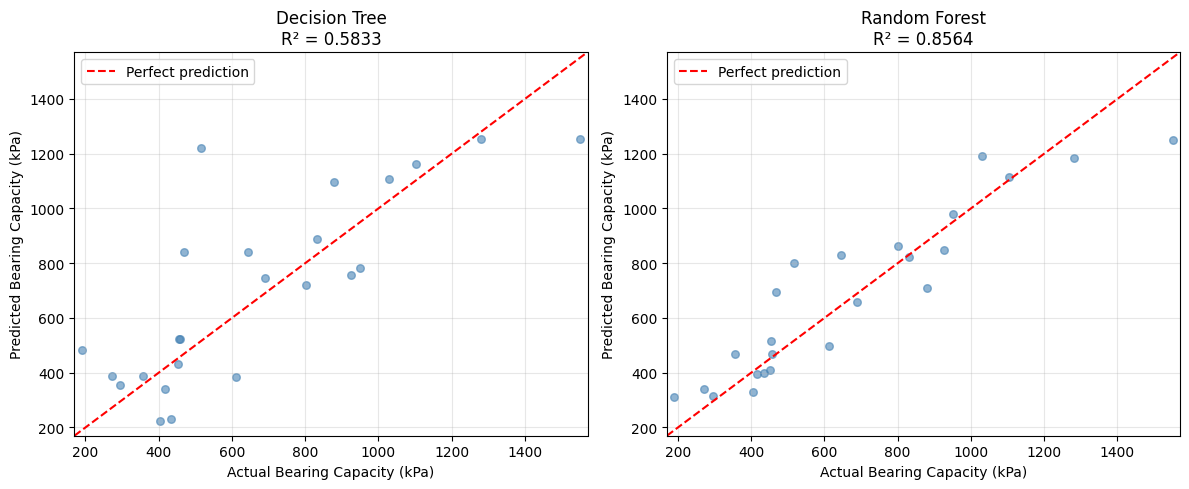

Random Forest predictions cluster more tightly around the perfect line.


In [7]:
# ─────────────────────────────────────────────────────
# PREDICTED vs ACTUAL COMPARISON
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_pred, title in zip(axes, [y_pred_dt, y_pred_rf], ['Decision Tree', 'Random Forest']):
    ax.scatter(y_test, y_pred, alpha=0.6, s=30, color='steelblue')
    lims = [min(y_test.min(), y_pred.min()) - 20, max(y_test.max(), y_pred.max()) + 20]
    ax.plot(lims, lims, 'r--', label='Perfect prediction')
    ax.set_xlabel('Actual Bearing Capacity (kPa)')
    ax.set_ylabel('Predicted Bearing Capacity (kPa)')
    ax.set_title(f'{title}\nR\u00b2 = {r2_score(y_test, y_pred):.4f}')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_xlim(lims)
    ax.set_ylim(lims)

plt.tight_layout()
plt.show()

print("Random Forest predictions cluster more tightly around the perfect line.")

---

## Part 4: Out-of-Bag (OOB) Score

/opt/anaconda3/lib/python3.12/site-packages/sklearn/ensemble/_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


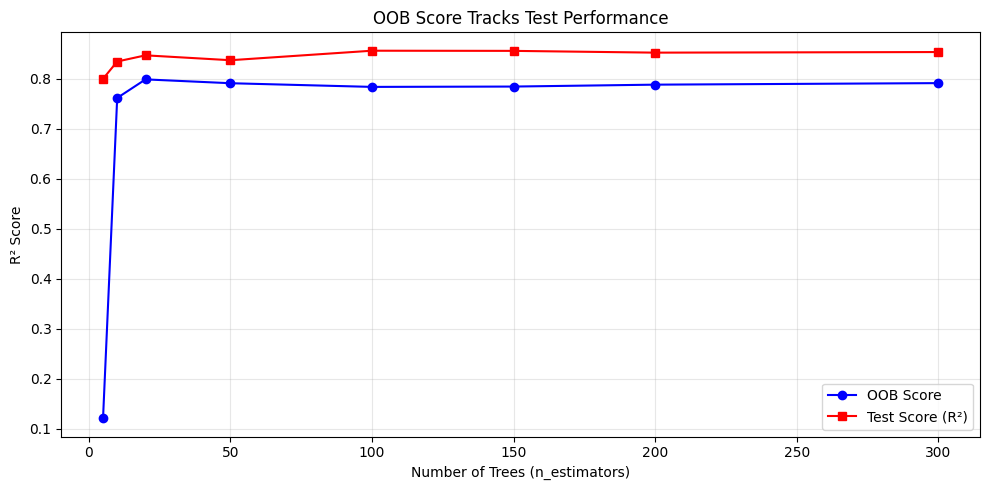

OOB score closely tracks test score — free validation!
Performance plateaus after ~100 trees (diminishing returns).


In [8]:
# ─────────────────────────────────────────────────────
# OOB SCORE vs TEST SCORE AS TREES GROW
# ─────────────────────────────────────────────────────

n_trees_range = [5, 10, 20, 50, 100, 150, 200, 300]
oob_scores = []
test_scores = []

for n in n_trees_range:
    rf_temp = RandomForestRegressor(n_estimators=n, random_state=42, oob_score=True)
    rf_temp.fit(X_train, y_train)
    oob_scores.append(rf_temp.oob_score_)
    test_scores.append(rf_temp.score(X_test, y_test))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(n_trees_range, oob_scores, 'b-o', label='OOB Score', markersize=6)
ax.plot(n_trees_range, test_scores, 'r-s', label='Test Score (R\u00b2)', markersize=6)
ax.set_xlabel('Number of Trees (n_estimators)')
ax.set_ylabel('R\u00b2 Score')
ax.set_title('OOB Score Tracks Test Performance')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("OOB score closely tracks test score — free validation!")
print("Performance plateaus after ~100 trees (diminishing returns).")

---

## Part 5: Feature Importance

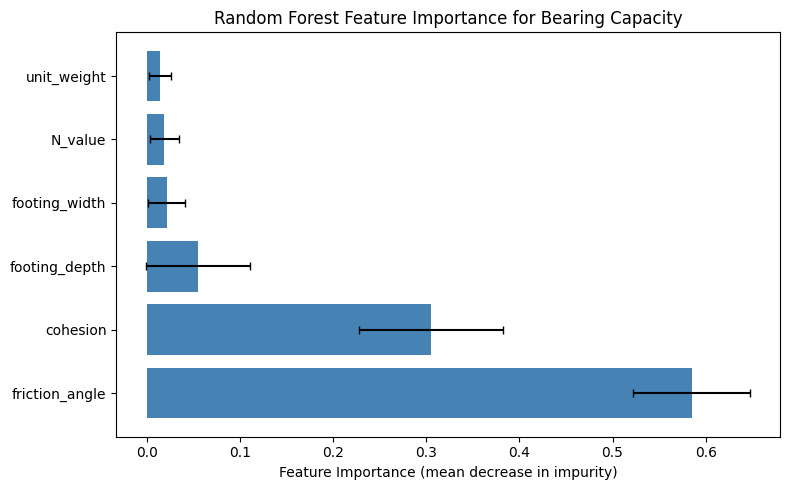

Feature Importance Ranking:
  friction_angle      : 0.5849 ± 0.0624
  cohesion            : 0.3051 ± 0.0774
  footing_depth       : 0.0552 ± 0.0555
  footing_width       : 0.0216 ± 0.0197
  N_value             : 0.0188 ± 0.0157
  unit_weight         : 0.0143 ± 0.0122

Error bars show variability across individual trees.
Cohesion and friction angle dominate — consistent with
Terzaghi's bearing capacity equation.


In [9]:
# ─────────────────────────────────────────────────────
# FEATURE IMPORTANCE FROM RANDOM FOREST
# ─────────────────────────────────────────────────────

importances = rf.feature_importances_
std = np.std([tree.feature_importances_ for tree in rf.estimators_], axis=0)
sorted_idx = np.argsort(importances)[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(
    [feature_cols[i] for i in sorted_idx],
    importances[sorted_idx],
    xerr=std[sorted_idx],
    color='steelblue',
    capsize=3
)
ax.set_xlabel('Feature Importance (mean decrease in impurity)')
ax.set_title('Random Forest Feature Importance for Bearing Capacity')
plt.tight_layout()
plt.show()

print("Feature Importance Ranking:")
print("=" * 50)
for i in sorted_idx:
    print(f"  {feature_cols[i]:<20s}: {importances[i]:.4f} \u00b1 {std[i]:.4f}")

print(f"\nError bars show variability across individual trees.")
print(f"Cohesion and friction angle dominate — consistent with")
print(f"Terzaghi's bearing capacity equation.")

---

## Part 6: Hyperparameters — n_estimators and max_depth

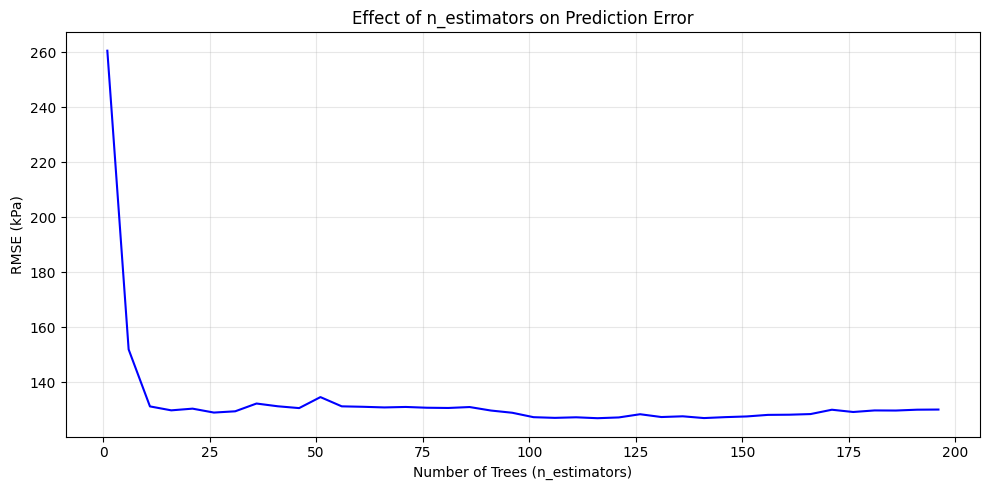

RMSE with 1 tree:   260.54 kPa
RMSE with 100 trees: 127.30 kPa
RMSE with 200 trees: 130.08 kPa

More trees always help (or at least don't hurt), but gains diminish.
100 trees is usually a good starting point.


In [10]:
# ─────────────────────────────────────────────────────
# EFFECT OF n_estimators
# ─────────────────────────────────────────────────────

n_range = list(range(1, 201, 5))
rmse_values = []

for n in n_range:
    rf_n = RandomForestRegressor(n_estimators=n, random_state=42)
    rf_n.fit(X_train, y_train)
    pred = rf_n.predict(X_test)
    rmse_values.append(np.sqrt(mean_squared_error(y_test, pred)))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(n_range, rmse_values, 'b-', linewidth=1.5)
ax.set_xlabel('Number of Trees (n_estimators)')
ax.set_ylabel('RMSE (kPa)')
ax.set_title('Effect of n_estimators on Prediction Error')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"RMSE with 1 tree:   {rmse_values[0]:.2f} kPa")
print(f"RMSE with 100 trees: {rmse_values[20]:.2f} kPa")
print(f"RMSE with 200 trees: {rmse_values[-1]:.2f} kPa")
print(f"\nMore trees always help (or at least don't hurt), but gains diminish.")
print(f"100 trees is usually a good starting point.")

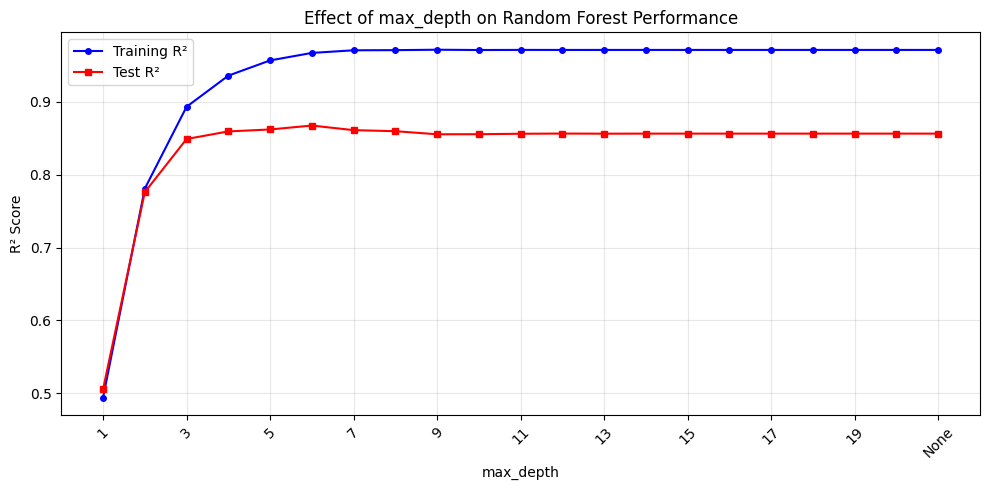

Best max_depth = 6, test R² = 0.8675

Unlike single trees, Random Forests are robust to max_depth.
Bagging already controls overfitting, so deep trees work well.


In [11]:
# ─────────────────────────────────────────────────────
# EFFECT OF max_depth
# ─────────────────────────────────────────────────────

depths = list(range(1, 21)) + [None]  # None = unlimited
depth_labels = [str(d) if d else 'None' for d in depths]
train_r2 = []
test_r2 = []

for d in depths:
    rf_d = RandomForestRegressor(n_estimators=100, max_depth=d, random_state=42)
    rf_d.fit(X_train, y_train)
    train_r2.append(rf_d.score(X_train, y_train))
    test_r2.append(rf_d.score(X_test, y_test))

fig, ax = plt.subplots(figsize=(10, 5))
x_pos = range(len(depths))
ax.plot(x_pos, train_r2, 'b-o', markersize=4, label='Training R\u00b2')
ax.plot(x_pos, test_r2, 'r-s', markersize=4, label='Test R\u00b2')
ax.set_xticks(x_pos[::2])
ax.set_xticklabels([depth_labels[i] for i in range(0, len(depths), 2)], rotation=45)
ax.set_xlabel('max_depth')
ax.set_ylabel('R\u00b2 Score')
ax.set_title('Effect of max_depth on Random Forest Performance')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

best_idx = np.argmax(test_r2)
print(f"Best max_depth = {depth_labels[best_idx]}, test R\u00b2 = {test_r2[best_idx]:.4f}")
print(f"\nUnlike single trees, Random Forests are robust to max_depth.")
print(f"Bagging already controls overfitting, so deep trees work well.")

---

## Part 7: Individual Trees vs the Forest

/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/va

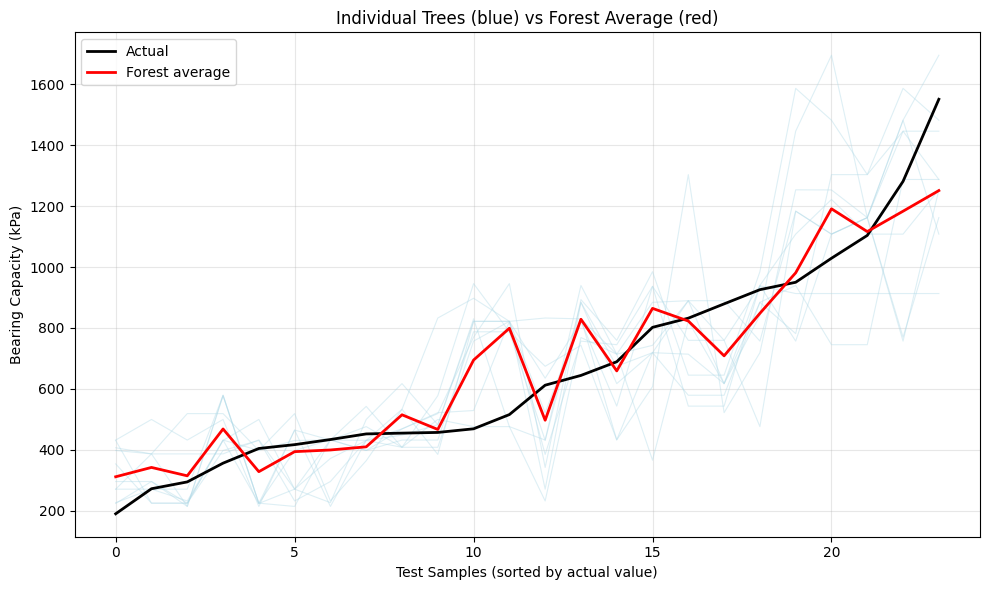

Light blue = individual tree predictions (noisy, high variance).
Red = forest average (smooth, lower variance, closer to actual).
This is the power of ensemble averaging!


In [12]:
# ─────────────────────────────────────────────────────
# VISUALIZE INDIVIDUAL TREE PREDICTIONS vs FOREST
# ─────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 6))

# Plot predictions from 10 individual trees
sample_idx = np.argsort(y_test.values)
x_axis = range(len(y_test))

for i in range(10):
    tree_pred = rf.estimators_[i].predict(X_test)
    ax.plot(x_axis, tree_pred[sample_idx], color='lightblue', alpha=0.4, linewidth=0.8)

ax.plot(x_axis, y_test.values[sample_idx], 'k-', linewidth=2, label='Actual', zorder=5)
ax.plot(x_axis, y_pred_rf[sample_idx], 'r-', linewidth=2, label='Forest average', zorder=5)

ax.set_xlabel('Test Samples (sorted by actual value)')
ax.set_ylabel('Bearing Capacity (kPa)')
ax.set_title('Individual Trees (blue) vs Forest Average (red)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Light blue = individual tree predictions (noisy, high variance).")
print("Red = forest average (smooth, lower variance, closer to actual).")
print("This is the power of ensemble averaging!")

---

## Part 8: Residual Analysis

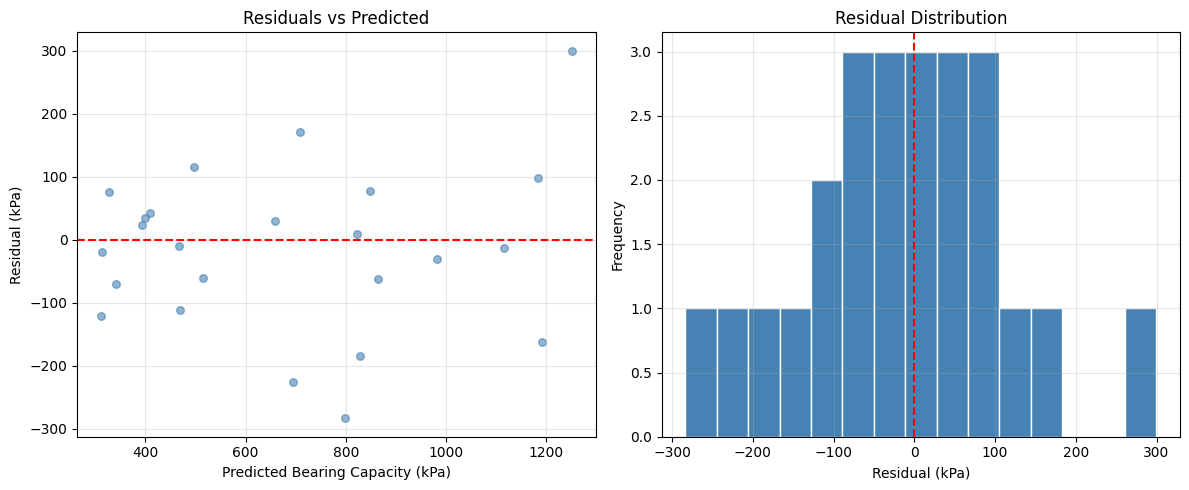

Mean residual: -15.80 kPa (should be near 0)
Std of residuals: 126.71 kPa

Residuals should be randomly scattered around zero.
No clear pattern = model captures the main trends well.


In [13]:
# ─────────────────────────────────────────────────────
# RESIDUAL ANALYSIS
# ─────────────────────────────────────────────────────

residuals = y_test.values - y_pred_rf

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Residual vs Predicted
axes[0].scatter(y_pred_rf, residuals, alpha=0.6, s=30, color='steelblue')
axes[0].axhline(y=0, color='r', linestyle='--')
axes[0].set_xlabel('Predicted Bearing Capacity (kPa)')
axes[0].set_ylabel('Residual (kPa)')
axes[0].set_title('Residuals vs Predicted')
axes[0].grid(True, alpha=0.3)

# Residual histogram
axes[1].hist(residuals, bins=15, color='steelblue', edgecolor='white')
axes[1].axvline(x=0, color='r', linestyle='--')
axes[1].set_xlabel('Residual (kPa)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Residual Distribution')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean residual: {residuals.mean():.2f} kPa (should be near 0)")
print(f"Std of residuals: {residuals.std():.2f} kPa")
print(f"\nResiduals should be randomly scattered around zero.")
print(f"No clear pattern = model captures the main trends well.")

---

## Part 9: Predict New Sites

In [14]:
# ─────────────────────────────────────────────────────
# PREDICT BEARING CAPACITY FOR NEW SITES
# ─────────────────────────────────────────────────────

new_sites = pd.DataFrame({
    'footing_width': [1.5, 2.5, 3.0, 1.0],
    'footing_depth': [1.0, 1.5, 2.0, 0.5],
    'N_value': [10, 25, 40, 8],
    'unit_weight': [16.0, 18.5, 20.0, 15.5],
    'cohesion': [15.0, 40.0, 60.0, 5.0],
    'friction_angle': [20.0, 28.0, 35.0, 18.0]
})

predictions = rf.predict(new_sites)

# Get prediction spread from individual trees
tree_preds = np.array([tree.predict(new_sites) for tree in rf.estimators_])
pred_std = tree_preds.std(axis=0)

print("Bearing Capacity Predictions for New Sites")
print("=" * 65)
for i in range(len(new_sites)):
    row = new_sites.iloc[i]
    print(f"\nSite {i+1}: B={row['footing_width']:.1f}m, D={row['footing_depth']:.1f}m, "
          f"N={row['N_value']:.0f}, c={row['cohesion']:.0f}kPa, \u03c6={row['friction_angle']:.0f}\u00b0")
    print(f"  Predicted bearing capacity: {predictions[i]:.1f} \u00b1 {pred_std[i]:.1f} kPa")

print(f"\nThe \u00b1 range comes from the spread of individual tree predictions.")
print(f"Larger spread = more uncertainty in the prediction.")

Bearing Capacity Predictions for New Sites

Site 1: B=1.5m, D=1.0m, N=10, c=15kPa, φ=20°
  Predicted bearing capacity: 314.1 ± 81.8 kPa

Site 2: B=2.5m, D=1.5m, N=25, c=40kPa, φ=28°
  Predicted bearing capacity: 651.9 ± 176.6 kPa

Site 3: B=3.0m, D=2.0m, N=40, c=60kPa, φ=35°
  Predicted bearing capacity: 1099.5 ± 196.6 kPa

Site 4: B=1.0m, D=0.5m, N=8, c=5kPa, φ=18°
  Predicted bearing capacity: 276.2 ± 84.9 kPa

The ± range comes from the spread of individual tree predictions.
Larger spread = more uncertainty in the prediction.


/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/va

---

## Practice Exercises

### Exercise 1: More Trees
Train a Random Forest with 500 trees. Does the RMSE improve compared to 100 trees? Is the extra computation time worth it?

### Exercise 2: Feature Subset Size
Try `max_features='sqrt'` vs `max_features=0.5` vs `max_features=None`. How does the feature subset size affect OOB score?

### Exercise 3: Compare with Single Tree
Train 5 different single decision trees (use different `random_state` values). Calculate the variance of their test RMSE values. Compare with the Random Forest's stability.

In [15]:
# EXERCISE 1: 500 trees
# rf_500 = RandomForestRegressor(n_estimators=500, random_state=42, oob_score=True)
# rf_500.fit(X_train, y_train)
# pred_500 = rf_500.predict(X_test)
# print(f"RMSE (500 trees): {np.sqrt(mean_squared_error(y_test, pred_500)):.2f} kPa")
# print(f"OOB Score: {rf_500.oob_score_:.4f}")

In [16]:
# EXERCISE 2: Feature subset size
# for mf in ['sqrt', 0.5, None]:
#     rf_mf = RandomForestRegressor(n_estimators=100, max_features=mf, random_state=42, oob_score=True)
#     rf_mf.fit(X_train, y_train)
#     print(f"max_features={str(mf):<6s}: OOB={rf_mf.oob_score_:.4f}, Test R2={rf_mf.score(X_test, y_test):.4f}")

---

## Key Takeaways

1. **Random Forest = many trees voting together**. By averaging predictions from 100+ trees trained on different bootstrap samples, variance drops dramatically while bias stays low.

2. **Out-of-Bag score provides free validation**. Each tree is validated on the ~37% of samples it never saw during training. OOB score closely tracks true test performance.

3. **Feature importance with uncertainty**. Unlike a single tree, Random Forest gives stable importance rankings with error bars from the variability across trees.

4. **n_estimators: more is (almost) always better**. Performance improves and then plateaus. 100-200 trees is usually sufficient. Unlike other hyperparameters, more trees cannot overfit.

5. **max_depth is less critical**. Bagging already controls overfitting, so Random Forests work well even with deep (unlimited depth) trees.

---

## How This Connects to ML

| What We Did Today | ML Equivalent |
|-------------------|---------------|
| Bearing capacity prediction | Regression with ensemble methods |
| Bootstrap sampling | Bagging (variance reduction) |
| OOB score tracking | Built-in cross-validation |
| Feature importance with error bars | Robust feature selection |
| n_estimators tuning | Ensemble size optimization |
| Individual trees vs forest | Bias-variance tradeoff visualization |
| Prediction spread from trees | Uncertainty quantification |

---

*Day 042 of 100 — One tree is an opinion; a forest is a consensus!*